In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv


1. Problem – Describe the prediction problem and response variable.

2. Data exploration – Examine the variables, missing values, response distribution, and several interesting relationships.

3. Data preparation – Explain how you handled missing values and categorical/numerical predictors.

4. Baseline model – Fit a logistic regression model and evaluate it using ROC AUC.

5. Additional models – Fit at least two additional supervised learning models.

6. Model comparison – Compare your models using the same validation procedure.

7. Model interpretation – Identify important predictors and discuss what your model suggests about the problem.

8. Kaggle submission – Submit predictions to Kaggle and report your competition score.

9. Reflection – Briefly discuss what worked, what did not, and what you would try next.

In [2]:
# Part 1 
import pandas as pd

train = pd.read_csv('/kaggle/input/competitions/playground-series-s6e10/train.csv')
test = pd.read_csv('/kaggle/input/competitions/playground-series-s6e10/test.csv')
example = pd.read_csv('/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv')

print(train.shape)
print(test.shape)

train.head()

(699635, 23)
(299844, 22)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


1. The goal is to predict a satisfaction response, the response variable is satisfaction. I think this is a classification problem 

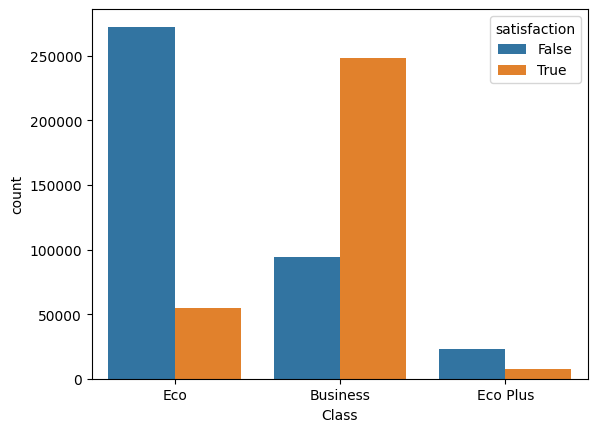

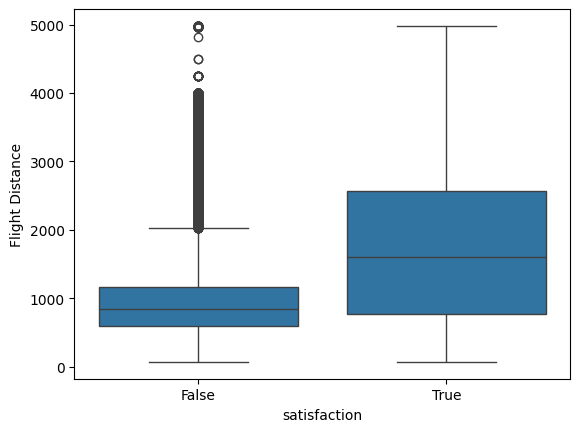

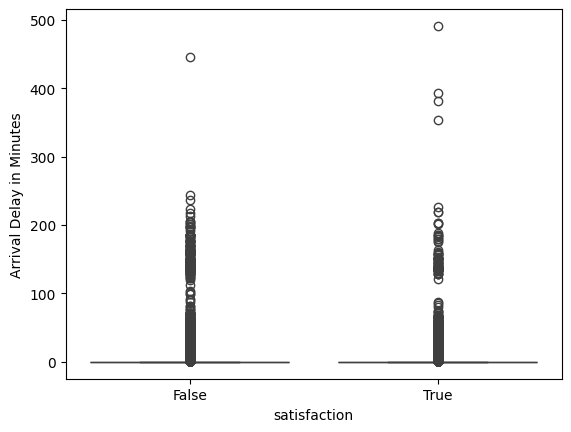

In [4]:
# 2. Data exploration – Examine the variables, missing values, response distribution, and several interesting relationships.
import seaborn as sns
import matplotlib.pyplot as plt

# look for missing values
train.isnull().sum().sort_values(ascending=False)
#arrival delay is the only variable with missing values, fill missing with departure delay
train[['Departure Delay in Minutes',
       'Arrival Delay in Minutes']].corr()

train['Arrival Delay in Minutes'] = train[
    'Arrival Delay in Minutes'
].fillna(train['Departure Delay in Minutes'])

# look at satisfaction
train['satisfaction'].value_counts()

# 389296 + 310339
# 389296/699635
# 55.64% were unsatisfied
# 310339/699635
# 44.35% were satisfied

# relationships
sns.countplot(
    x='Class',
    hue='satisfaction',
    data=train
)
plt.show()
#buisness class was the most satisfied

sns.boxplot(
    x='satisfaction',
    y='Flight Distance',
    data=train
)
plt.show()

sns.boxplot(
    x='satisfaction',
    y='Arrival Delay in Minutes',
    data=train
)
plt.show()

3. Data preparation – Explain how you handled missing values and categorical/numerical predictors:
   I found that arrival delay was the only variable with missing values, and after checking the correlation with departure delay I decided to fill the missing values for arrival with their corresponding departure delay values

For categorical predictors I used dummy variables to make them into a categorical numeric

In [5]:
#3 
train['Gender'] = train['Gender'].map({
    'Male': 0,
    'Female': 1
})

train['Customer Type'] = train['Customer Type'].map({
    'Loyal Customer': 1,
    'disloyal Customer': 0
})
train['satisfaction'] = train['satisfaction'].map({
    True: 1,
    False: 0
})

train['Class'] = train['Class'].map({
    'Eco': 3,
    'Eco Plus': 2,
    'Business': 1
})

train['Type of Travel'] = train['Type of Travel'].map({
    'Business travel': 1,
    'Personal Travel': 0
})


train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,1,1,0,3,0
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,0,1,1,1,1
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,1,1,0,3,0
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,0,1,0,3,0
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,1,0,1,3,0


In [6]:
# 4. Baseline model – Fit a logistic regression model and evaluate it using ROC AUC.
from sklearn.impute import SimpleImputer
X = train.drop("satisfaction", axis=1)
y = train["satisfaction"]

categorical_cols = X.select_dtypes(
    include=["object"]
).columns

numerical_cols = X.select_dtypes(
    exclude=["object"]
).columns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
)

from sklearn.linear_model import LogisticRegression
model = Pipeline([
    ("preprocessor", preprocessor),
    ("logreg", LogisticRegression(
        max_iter=1000,
        random_state=1
    ))
])
model.fit(X_train, y_train)

preds = model.predict(X_valid)
probs = model.predict_proba(X_valid)[:, 1]

from sklearn.metrics import roc_auc_score

roc_auc_score(y_valid, probs)

np.float64(0.9219847205249514)

The baseline logistic regression model achieved an ROC-AUC score of 0.922, strong baseline

In [7]:
#5 
#Try KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("knn", KNeighborsClassifier(n_neighbors=10))
])

knn_model.fit(X_train, y_train)

knn_probs = knn_model.predict_proba(X_valid)[:, 1]

knn_auc = roc_auc_score(y_valid, knn_probs)

print("KNN AUC:", knn_auc)

KNN AUC: 0.9442395158858755


The KNN model achieced an ROC-AUC score of 0.944, slightly higher than the baseline model

In [8]:
#Try Decision Trees
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("tree", DecisionTreeClassifier(
        max_depth=5,
        random_state=1
    ))
])

tree_model.fit(X_train, y_train)

tree_probs = tree_model.predict_proba(X_valid)[:, 1]

tree_auc = roc_auc_score(y_valid, tree_probs)

print("Decision Tree AUC:", tree_auc)

Decision Tree AUC: 0.9375183225638237


The decision tree ROC-AUC score was 0.937, slightly worse than the KNN model

In [9]:
# Try Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("rf", RandomForestClassifier(
        n_estimators=500,
        random_state=1
    ))
])

rf_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight enter...
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index([], dtype='object'))])),
                ('rf',
                 RandomForestClassifier(n_estimators=500, random_state=1))])

In [11]:
rf_probs = rf_model.predict_proba(X_valid)[:, 1]

rf_auc = roc_auc_score(y_valid, rf_probs)

print("Random Foreset AUC:", rf_auc)

Random Foreset AUC: 0.9547433978249423


the random forest ROC score was 0.955, better than my other models

In [22]:
rf_test_probs = rf_model.predict_proba(test)[:, 1]

submission = pd.DataFrame({
    "id": test["id"],
    "satisfaction": rf_test_probs
})

submission.to_csv("submission.csv", index=False)

In [23]:
submission.head()

,id,satisfaction
0,699635,0.292
1,699636,0.886
2,699637,0.786
3,699638,0.202
4,699639,0.086
